# Benchmark: carga y espacio de las estrategias de k-mers

**Responsable:** Juan Arias

**Objetivo:** comparar la estrategia principal (colección `kmers`, MODELO.md) con la alternativa embebida
(`tes_embebidos`) en tiempo de carga y espacio en disco. Los tiempos vienen de `03_pipeline_kmers.ipynb`
(`resultados/benchmark_carga.csv`). El benchmark de consultas está en `06_benchmark.ipynb` (Thomas).

Modelo de referencia: `../MODELO.md`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pymongo import MongoClient

DB_NAME = "panteon_prueba"
RESULTADOS = Path("../resultados")
FIGURAS = Path("../figuras")
FIGURAS.mkdir(exist_ok=True)

client = MongoClient("mongodb://localhost:27017")
db = client[DB_NAME]
db_bench = client[f"{DB_NAME}_bench"]

## 1. Tiempos de carga

In [2]:
carga = pd.read_csv(RESULTADOS / "benchmark_carga.csv")
carga = carga[carga["base"].isin([DB_NAME, db_bench.name])].reset_index(drop=True)
assert len(carga) == 2, f"Faltan filas de {DB_NAME} en benchmark_carga.csv: ejecutar 03_pipeline_kmers.ipynb"
carga["t_total_s"] = carga[["t_calculo_s", "t_insercion_s", "t_indices_s"]].sum(axis=1)
carga

,estrategia,base,n_tes,n_docs,t_calculo_s,t_insercion_s,t_indices_s,t_total_s
0,coleccion_kmers,panteon_prueba,25,150,0.005,0.004,0.086,0.095
1,embebido_en_tes,panteon_prueba_bench,25,25,0.005,0.006,0.036,0.047


## 2. Espacio (`collStats`)

In [3]:
def estadisticas(base, coleccion, estrategia):
    st = base.command("collStats", coleccion)
    fila = {
        "estrategia": estrategia, "base": base.name, "coleccion": coleccion,
        "count": st["count"], "size": st["size"], "avgObjSize": st.get("avgObjSize", 0),
        "storageSize": st["storageSize"], "totalIndexSize": st["totalIndexSize"],
    }
    fila.update({f"idx_{nombre}": tam for nombre, tam in st["indexSizes"].items()})
    return fila


espacio = pd.DataFrame([
    estadisticas(db, "kmers", "coleccion_kmers"),
    estadisticas(db_bench, "tes_embebidos", "embebido_en_tes"),
    estadisticas(db, "tes", "referencia_tes"),
])
espacio.to_csv(RESULTADOS / "benchmark_espacio.csv", index=False)
espacio.T

,0,1,2
estrategia,coleccion_kmers,embebido_en_tes,referencia_tes
base,panteon_prueba,panteon_prueba_bench,panteon_prueba
coleccion,kmers,tes_embebidos,tes
count,150,25,25
size,402902,398567,7725
avgObjSize,2686,15942,309
storageSize,159744,163840,20480
totalIndexSize,81920,40960,102400
idx__id_,20480,20480,20480
idx_te_id_1_k_1,20480.0,NaN,NaN


`size` es el tamaño sin comprimir de los documentos; `storageSize` es lo que ocupan en disco con la compresión de WiredTiger. Todos los tamaños están en bytes. `tes` es solo referencia: la estrategia embebida contiene una copia de `tes` más los k-mers.

## 3. Figuras

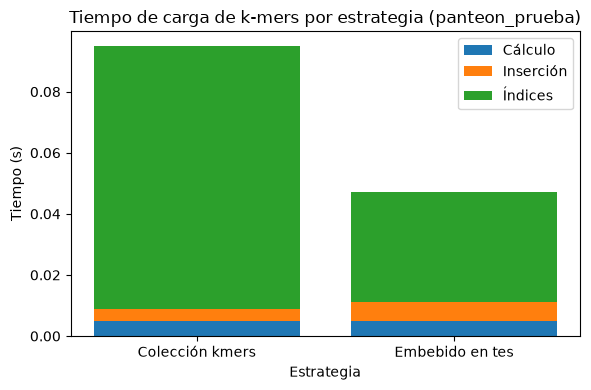

In [4]:
NOMBRES = {"coleccion_kmers": "Colección kmers", "embebido_en_tes": "Embebido en tes", "referencia_tes": "tes (referencia)"}

fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = carga["estrategia"].map(NOMBRES)
abajo = 0
for columna, nombre in [("t_calculo_s", "Cálculo"), ("t_insercion_s", "Inserción"), ("t_indices_s", "Índices")]:
    ax.bar(etiquetas, carga[columna], bottom=abajo, label=nombre)
    abajo = abajo + carga[columna]
ax.set_title(f"Tiempo de carga de k-mers por estrategia ({DB_NAME})")
ax.set_xlabel("Estrategia")
ax.set_ylabel("Tiempo (s)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / f"benchmark_carga_{DB_NAME}.png", dpi=300)
plt.show()

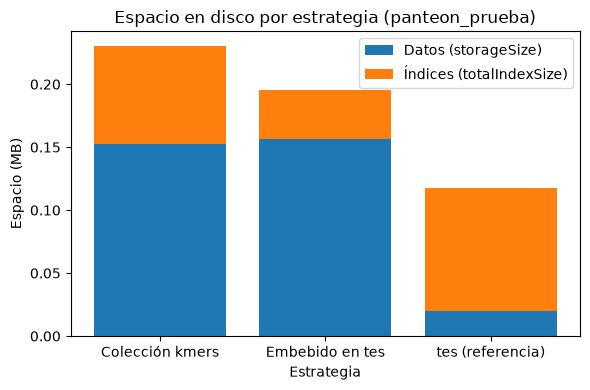

In [5]:
MB = 1024 ** 2
fig, ax = plt.subplots(figsize=(6, 4))
etiquetas = espacio["estrategia"].map(NOMBRES)
ax.bar(etiquetas, espacio["storageSize"] / MB, label="Datos (storageSize)")
ax.bar(etiquetas, espacio["totalIndexSize"] / MB, bottom=espacio["storageSize"] / MB, label="Índices (totalIndexSize)")
ax.set_title(f"Espacio en disco por estrategia ({DB_NAME})")
ax.set_xlabel("Estrategia")
ax.set_ylabel("Espacio (MB)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / f"benchmark_espacio_{DB_NAME}.png", dpi=300)
plt.show()

## 4. Interpretación

**Con `panteon_prueba` solo se valida que el notebook funciona:** con 25 TEs los tiempos son de
milisegundos y el espacio lo dominan los mínimos de WiredTiger por colección e índice, así que las cifras no
sirven para comparar. Las conclusiones se sacan al ejecutar con `DB_NAME = "panteon"`.

Qué mirar con la base real:

- **Cálculo:** debería ser casi igual en las dos estrategias, porque ambas usan `src/kmers.py` sobre las
  mismas secuencias; la diferencia está en armar 6 documentos por TE o uno solo.
- **Inserción:** `kmers` inserta 6 veces más documentos, pero más pequeños; `tes_embebidos` inserta documentos
  grandes que además copian todos los campos de `tes`.
- **Índices:** `kmers` necesita tres índices sobre ~1,44 millones de entradas; la embebida indexa una entrada
  por TE, así que su `totalIndexSize` debería ser mucho menor.
- **Datos:** `kmers` repite `te_id`, `pdb_id` y `te_order` en cada documento; la embebida evita esa
  repetición pero duplica `tes` completa. Comparar su `storageSize` restando la referencia de `tes`.
- El espacio es solo una parte de la decisión: el costo de las consultas (un solo k, heatmap por orden)
  está en el benchmark de consultas de Thomas.